In [1]:
import sys
import platform

print("Python:", sys.version.split()[0])
print("Processor:", platform.machine())
print("Environment:", sys.executable)

Python: 3.12.15
Processor: arm64
Environment: /Users/arun/Documents/Research Project/R1/python_Env/.venv/bin/python


In [18]:
from pathlib import Path

BASE = Path.home() / "Documents/Research Project/R1/python_Env"

# Change this when switching datasets
DATASET_NAME = "srilanka_supermarket_raw_pos.csv"

DATASET = BASE / "data" / DATASET_NAME

# Unique experiment folder for each dataset
EXPERIMENT_NAME = Path(DATASET_NAME).stem

EXPERIMENT_DIR = (
    BASE / "experiments" / EXPERIMENT_NAME
)

script = BASE / "component3_recommendation_experiment.py"

print("Dataset:", DATASET)
print("Experiment output:", EXPERIMENT_DIR)
print("Dataset exists:", DATASET.exists())

Dataset: /Users/arun/Documents/Research Project/R1/python_Env/data/srilanka_supermarket_raw_pos.csv
Experiment output: /Users/arun/Documents/Research Project/R1/python_Env/experiments/srilanka_supermarket_raw_pos
Dataset exists: True


In [3]:
from pathlib import Path
import pandas as pd
import json

base = Path.home() / "Documents/Research Project/R1/python_Env"
outputs = base / "outputs"

validation = pd.read_csv(outputs / "validation_results.csv")

with open(outputs / "final_test_result.json") as f:
    final_test = json.load(f)

print("VALIDATION RESULTS")
display(validation)

print("\nFINAL TEST RESULTS")
print(json.dumps(final_test, indent=2))

VALIDATION RESULTS


,Model,Queries,HitRate@5,NDCG@5
0,Hybrid-0.9,2640,0.2159,0.1314
1,Hybrid-0.5,2640,0.2144,0.1303
2,Hybrid-0.6,2640,0.2144,0.1303
3,Hybrid-0.7,2640,0.2140,0.1302
4,Hybrid-0.1,2640,0.2136,0.1300
5,Hybrid-0.2,2640,0.2136,0.1300
6,Hybrid-0.3,2640,0.2136,0.1300
7,Hybrid-0.4,2640,0.2136,0.1300
8,Hybrid-0.8,2640,0.2133,0.1300
9,FP-Growth,2640,0.2133,0.1298



FINAL TEST RESULTS
{
  "selected_model": "Hybrid-0.9",
  "metrics": {
    "Queries": 2642,
    "HitRate@5": 0.2169,
    "NDCG@5": 0.1329
  },
  "split": {
    "train": 14000,
    "validation": 3000,
    "test": 3000
  },
  "seed": 42,
  "k": 5
}


In [4]:
import matplotlib.pyplot as plt

print("Available columns:", validation.columns.tolist())
display(validation.head())

Matplotlib is building the font cache; this may take a moment.


Available columns: ['Model', 'Queries', 'HitRate@5', 'NDCG@5']


,Model,Queries,HitRate@5,NDCG@5
0,Hybrid-0.9,2640,0.2159,0.1314
1,Hybrid-0.5,2640,0.2144,0.1303
2,Hybrid-0.6,2640,0.2144,0.1303
3,Hybrid-0.7,2640,0.2140,0.1302
4,Hybrid-0.1,2640,0.2136,0.1300


In [5]:
import matplotlib.pyplot as plt

print("Available columns:", validation.columns.tolist())
display(validation.head())

Available columns: ['Model', 'Queries', 'HitRate@5', 'NDCG@5']


,Model,Queries,HitRate@5,NDCG@5
0,Hybrid-0.9,2640,0.2159,0.1314
1,Hybrid-0.5,2640,0.2144,0.1303
2,Hybrid-0.6,2640,0.2144,0.1303
3,Hybrid-0.7,2640,0.2140,0.1302
4,Hybrid-0.1,2640,0.2136,0.1300


Columns: ['Model', 'Queries', 'HitRate@5', 'NDCG@5']
Model column: Model
HitRate column: HitRate@5
NDCG column: NDCG@5


,Model,HitRate@5,NDCG@5
0,Hybrid-0.9,0.2159,0.1314
1,Hybrid-0.5,0.2144,0.1303
2,Hybrid-0.6,0.2144,0.1303
3,Hybrid-0.7,0.2140,0.1302
4,Hybrid-0.1,0.2136,0.1300
5,Hybrid-0.2,0.2136,0.1300
6,Hybrid-0.3,0.2136,0.1300
7,Hybrid-0.4,0.2136,0.1300
8,Hybrid-0.8,0.2133,0.1300
9,FP-Growth,0.2133,0.1298


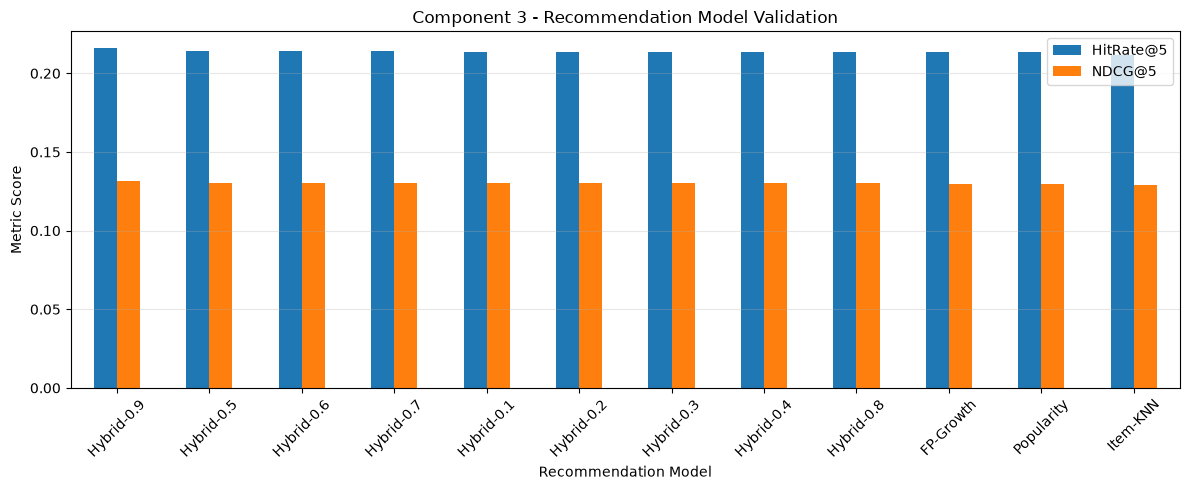

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Check actual column names
print("Columns:", validation.columns.tolist())

# Identify columns without assuming exact capitalization
def find_column(columns, keywords):
    for col in columns:
        normalized = col.lower().replace("_", "").replace(" ", "")
        if all(word in normalized for word in keywords):
            return col
    return None

model_col = find_column(validation.columns, ["model"])
hit_col = find_column(validation.columns, ["hit"])
ndcg_col = find_column(validation.columns, ["ndcg"])

print("Model column:", model_col)
print("HitRate column:", hit_col)
print("NDCG column:", ndcg_col)

if not all([model_col, hit_col, ndcg_col]):
    print("Could not identify all required columns.")
    display(validation.head())
else:
    results = validation[[model_col, hit_col, ndcg_col]].copy()
    results[hit_col] = pd.to_numeric(results[hit_col], errors="coerce")
    results[ndcg_col] = pd.to_numeric(results[ndcg_col], errors="coerce")
    results = results.dropna()

    display(results)

    ax = results.set_index(model_col)[[hit_col, ndcg_col]].plot(
        kind="bar",
        figsize=(12, 5),
        rot=45
    )

    ax.set_title("Component 3 - Recommendation Model Validation")
    ax.set_ylabel("Metric Score")
    ax.set_xlabel("Recommendation Model")
    ax.legend(["HitRate@5", "NDCG@5"])
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

Average basket size: 4.51
Minimum: 1
Maximum: 8


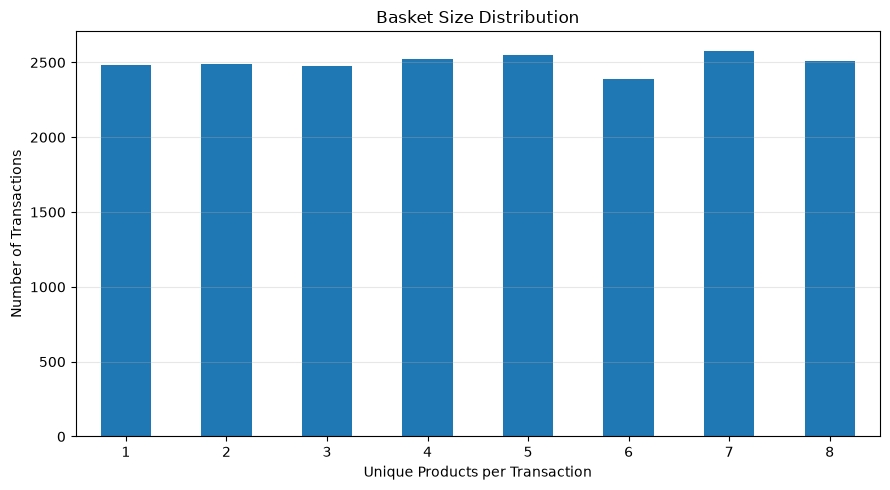

In [7]:
import matplotlib.pyplot as plt

basket_sizes = df.groupby("Transaction_ID")["Product_Name"].nunique()

print("Average basket size:", round(basket_sizes.mean(), 2))
print("Minimum:", basket_sizes.min())
print("Maximum:", basket_sizes.max())

plt.figure(figsize=(9, 5))

basket_sizes.value_counts().sort_index().plot(kind="bar")

plt.title("Basket Size Distribution")
plt.xlabel("Unique Products per Transaction")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

,Units Sold
Product_Name,
Sunlight Lemon Soap 120g,5129
Munchee Super Cream Cracker 125g,4682
Pelwatte Full Cream Milk Powder 400g,4409
White Sugar 1kg,4357
Prima Kottu Mee Chicken 80g,4221
Watawala Tea 200g,4058
Anchor Full Cream Milk Powder 1kg,4045
Newdale Strawberry Yogurt 80g,3972
Maliban Gold Marie 80g,3958


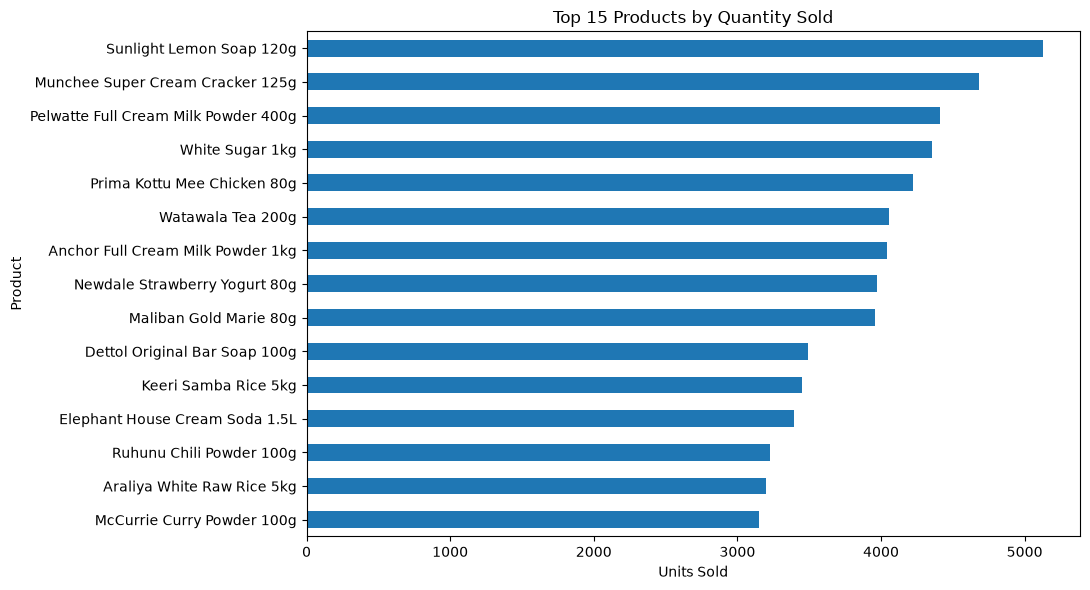

In [8]:
product_counts = (
    df.groupby("Product_Name")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

display(product_counts.to_frame("Units Sold"))

plt.figure(figsize=(11, 6))

product_counts.sort_values().plot(kind="barh")

plt.title("Top 15 Products by Quantity Sold")
plt.xlabel("Units Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

,Transactions Containing Category
Category,
Snacks & Biscuits,11964
Dairy & Chilled,11490
Household & Personal Care,11323
Staples & Essentials,10694
Beverages,10250
Condiments & Baking,8646


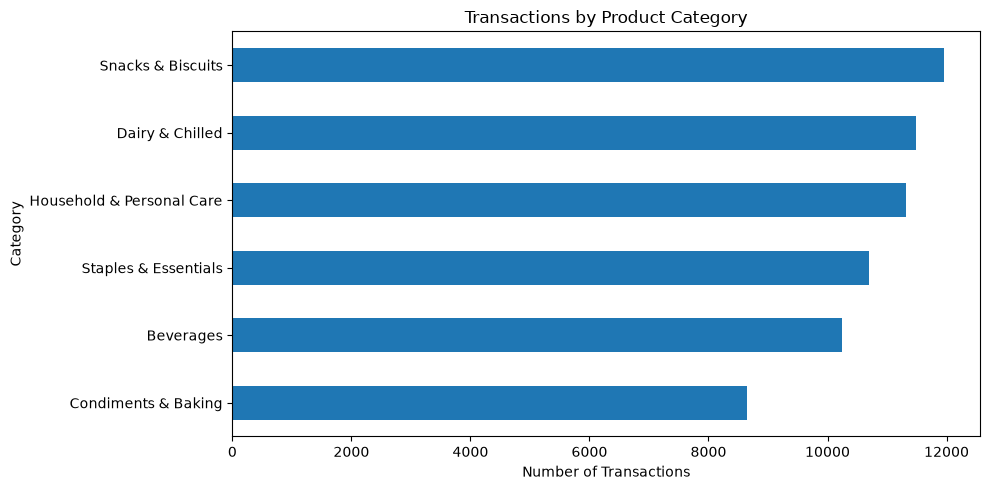

In [9]:
category_counts = (
    df.groupby("Category")["Transaction_ID"]
    .nunique()
    .sort_values(ascending=False)
)

display(category_counts.to_frame("Transactions Containing Category"))

plt.figure(figsize=(10, 5))

category_counts.sort_values().plot(kind="barh")

plt.title("Transactions by Product Category")
plt.xlabel("Number of Transactions")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

Saved rules: 100
Columns: ['antecedents', 'consequents', 'antecedent support', 'consequent support', 'support', 'confidence', 'lift', 'representativity', 'leverage', 'conviction', 'zhangs_metric', 'jaccard', 'certainty', 'kulczynski']


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({'Dettol Original Bar Soap 100g'}),frozenset({'Highland Butter Salted 200g'}),0.130214,0.064929,0.011000,0.084476,1.301063,1.0,0.002545,1.021351,0.266040,0.059736,0.020905,0.126947
1,frozenset({'Highland Butter Salted 200g'}),frozenset({'Dettol Original Bar Soap 100g'}),0.064929,0.130214,0.011000,0.169417,1.301063,1.0,0.002545,1.047199,0.247465,0.059736,0.045072,0.126947
2,frozenset({'Munchee Lemon Puff 200g'}),frozenset({'Astra Margarine Tub 250g'}),0.115500,0.099571,0.014643,0.126778,1.273237,1.0,0.003142,1.031157,0.242623,0.073058,0.030215,0.136918
3,frozenset({'Astra Margarine Tub 250g'}),frozenset({'Munchee Lemon Puff 200g'}),0.099571,0.115500,0.014643,0.147059,1.273237,1.0,0.003142,1.037000,0.238331,0.073058,0.035680,0.136918
4,frozenset({'Vim Dishwash Liquid 500ml'}),frozenset({'Lifebuoy Total Bar Soap 100g'}),0.099429,0.113429,0.014071,0.141523,1.247684,1.0,0.002793,1.032726,0.220432,0.070787,0.031689,0.132789



Association Rule Statistics
count    100.000000
mean       1.185492
std        0.031612
min        1.153825
25%        1.161902
50%        1.177034
75%        1.192989
max        1.301063
Name: lift, dtype: float64

Rules with lift >= 1.2: 20
Rules with lift >= 1.5: 0


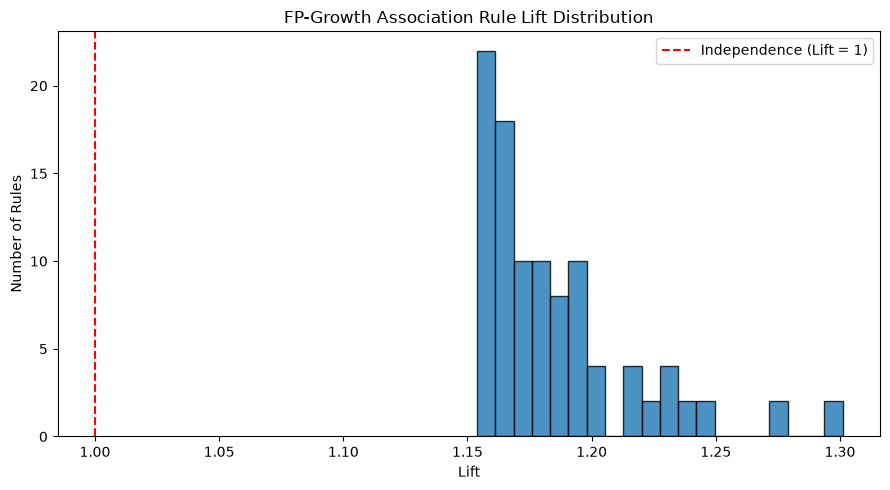

In [10]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

base = Path.home() / "Documents/Research Project/R1/python_Env"
rules_path = base / "outputs" / "top_rules.csv"

rules = pd.read_csv(rules_path)

print("Saved rules:", len(rules))
print("Columns:", rules.columns.tolist())

display(rules.head())

if "lift" in rules.columns:
    print("\nAssociation Rule Statistics")
    print(rules["lift"].describe())

    print("\nRules with lift >= 1.2:",
          (rules["lift"] >= 1.2).sum())

    print("Rules with lift >= 1.5:",
          (rules["lift"] >= 1.5).sum())

    plt.figure(figsize=(9, 5))

    plt.hist(
        rules["lift"].dropna(),
        bins=20,
        edgecolor="black",
        alpha=0.8
    )

    plt.axvline(
        1.0,
        linestyle="--",
        color="red",
        label="Independence (Lift = 1)"
    )

    plt.title("FP-Growth Association Rule Lift Distribution")
    plt.xlabel("Lift")
    plt.ylabel("Number of Rules")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [11]:
if "lift" in rules.columns:
    strongest_rules = rules.sort_values(
        by="lift",
        ascending=False
    ).head(15)

    display(strongest_rules)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({'Dettol Original Bar Soap 100g'}),frozenset({'Highland Butter Salted 200g'}),0.130214,0.064929,0.011000,0.084476,1.301063,1.0,0.002545,1.021351,0.266040,0.059736,0.020905,0.126947
1,frozenset({'Highland Butter Salted 200g'}),frozenset({'Dettol Original Bar Soap 100g'}),0.064929,0.130214,0.011000,0.169417,1.301063,1.0,0.002545,1.047199,0.247465,0.059736,0.045072,0.126947
2,frozenset({'Munchee Lemon Puff 200g'}),frozenset({'Astra Margarine Tub 250g'}),0.115500,0.099571,0.014643,0.126778,1.273237,1.0,0.003142,1.031157,0.242623,0.073058,0.030215,0.136918
3,frozenset({'Astra Margarine Tub 250g'}),frozenset({'Munchee Lemon Puff 200g'}),0.099571,0.115500,0.014643,0.147059,1.273237,1.0,0.003142,1.037000,0.238331,0.073058,0.035680,0.136918
4,frozenset({'Vim Dishwash Liquid 500ml'}),frozenset({'Lifebuoy Total Bar Soap 100g'}),0.099429,0.113429,0.014071,0.141523,1.247684,1.0,0.002793,1.032726,0.220432,0.070787,0.031689,0.132789
5,frozenset({'Lifebuoy Total Bar Soap 100g'}),frozenset({'Vim Dishwash Liquid 500ml'}),0.113429,0.099429,0.014071,0.124055,1.247684,1.0,0.002793,1.028115,0.223913,0.070787,0.027346,0.132789
6,frozenset({'Prima Kottu Mee Chicken 80g'}),frozenset({'Astra Margarine Tub 250g'}),0.157286,0.099571,0.019357,0.123070,1.235996,1.0,0.003696,1.026796,0.226573,0.081504,0.026097,0.158737
7,frozenset({'Astra Margarine Tub 250g'}),frozenset({'Prima Kottu Mee Chicken 80g'}),0.099571,0.157286,0.019357,0.194405,1.235996,1.0,0.003696,1.046076,0.212050,0.081504,0.044047,0.158737
8,frozenset({'Dilmah Premium Tea Pack 100g'}),frozenset({'Fortune Vegetable Oil 1L'}),0.085429,0.116000,0.012214,0.142977,1.232557,1.0,0.002305,1.031477,0.206302,0.064553,0.030517,0.124136
9,frozenset({'Fortune Vegetable Oil 1L'}),frozenset({'Dilmah Premium Tea Pack 100g'}),0.116000,0.085429,0.012214,0.105296,1.232557,1.0,0.002305,1.022205,0.213437,0.064553,0.021723,0.124136


In [5]:
from pathlib import Path
import ast

BASE = Path.home() / "Documents/Research Project/R1/python_Env"

scripts = [
    "component3_recommendation_experiment.py",
    "experiment5_personalized.py",
]

for script_name in scripts:
    path = BASE / script_name

    print(f"\n--- {script_name} ---")
    print("Exists:", path.exists())

    if not path.exists():
        continue

    tree = ast.parse(path.read_text(encoding="utf-8"))

    functions = [
        node.name
        for node in tree.body
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
    ]

    print("Functions:", functions)


--- component3_recommendation_experiment.py ---
Exists: True
Functions: ['make_queries', 'evaluate', 'main']

--- experiment5_personalized.py ---
Exists: True
Functions: []


In [4]:
for script_name in scripts:
    path = BASE / script_name

    if not path.exists():
        continue

    print(f"\n--- {script_name} ---")

    for line_number, line in enumerate(
        path.read_text(encoding="utf-8").splitlines(),
        start=1
    ):
        if any(keyword in line for keyword in [
            "to_csv(",
            "json.dump(",
            "to_pickle(",
            "joblib.dump(",
            "pickle.dump(",
            "savefig(",
            "OUTPUT",
            "output_dir",
        ]):
            print(f"{line_number}: {line.strip()}")


--- component3_recommendation_experiment.py ---
105: rules.sort_values('lift', ascending=False).head(100).to_csv(output / 'top_rules.csv', index=False)
149: validation.to_csv(output / 'validation_results.csv', index=False)
157: json.dump({'selected_model': best_name, 'metrics': final_test,

--- experiment5_personalized.py ---


In [6]:
from pathlib import Path

BASE = Path.home() / "Documents/Research Project/R1/python_Env"

script = BASE / "component3_recommendation_experiment.py"
lines = script.read_text(encoding="utf-8").splitlines()

print("=== TRAINING CONFIGURATION AND MAIN FUNCTION ===")

for i, line in enumerate(lines, start=1):
    if (
        i <= 45
        or "def main(" in line
        or "output =" in line
        or "read_csv(" in line
        or "train_test_split" in line
        or "__main__" in line
    ):
        print(f"{i:03d}: {line}")

=== TRAINING CONFIGURATION AND MAIN FUNCTION ===
001: #!/usr/bin/env python3
002: """Leakage-aware Component 3 recommendation benchmark for Sri Lankan POS baskets."""
003: from pathlib import Path
004: import argparse
005: import json
006: import numpy as np
007: import pandas as pd
008: from scipy.sparse import csr_matrix
009: from sklearn.metrics.pairwise import cosine_similarity
010: from mlxtend.frequent_patterns import fpgrowth, association_rules
011: 
012: SEED = 42
013: K = 5
014: REQUIRED = {'Transaction_ID', 'Product_Name', 'Timestamp'}
015: 
016: 
017: def make_queries(baskets, seed=SEED):
018:     rng = np.random.default_rng(seed)
019:     result = []
020:     for basket in baskets:
021:         if len(basket) < 2:
022:             continue
023:         target = basket[int(rng.integers(len(basket)))]
024:         result.append((set(basket) - {target}, target))
025:     return result
026: 
027: 
028: def evaluate(queries, recommend, k=K):
029:     if not queries:
030:        

In [7]:
import subprocess
import sys
from pathlib import Path

BASE = Path.home() / "Documents/Research Project/R1/python_Env"

script = BASE / "component3_recommendation_experiment.py"

result = subprocess.run(
    [sys.executable, str(script), "--help"],
    cwd=BASE,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)

usage: component3_recommendation_experiment.py [-h] --csv CSV
                                               [--output OUTPUT]

options:
  -h, --help       show this help message and exit
  --csv CSV        Path to POS CSV
  --output OUTPUT



In [8]:
from pathlib import Path

DATASET = BASE / "data" / "srilanka_supermarket_raw_pos.csv"

EXPERIMENT_DIR = (
    BASE / "experiments" / "notebook_experiment_01"
)

print("Dataset exists:", DATASET.is_file())
print("Training script exists:", script.is_file())
print("New experiment folder:", EXPERIMENT_DIR)
print("Folder already exists:", EXPERIMENT_DIR.exists())

Dataset exists: True
Training script exists: True
New experiment folder: /Users/arun/Documents/Research Project/R1/python_Env/experiments/notebook_experiment_01
Folder already exists: False


In [9]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, str(script), "--help"],
    cwd=BASE,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("ERROR:", result.stderr)

usage: component3_recommendation_experiment.py [-h] --csv CSV
                                               [--output OUTPUT]

options:
  -h, --help       show this help message and exit
  --csv CSV        Path to POS CSV
  --output OUTPUT



In [10]:
import ast

source = script.read_text(encoding="utf-8")
tree = ast.parse(source)

main_function = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef) and node.name == "main"
)

lines = source.splitlines()

start = main_function.lineno
end = main_function.end_lineno

print(f"Main function: lines {start}–{end}\n")

for line_number in range(start, end + 1):
    print(f"{line_number:03d}: {lines[line_number - 1]}")

Main function: lines 41–160

041: def main():
042:     parser = argparse.ArgumentParser()
043:     parser.add_argument('--csv', required=True, help='Path to POS CSV')
044:     parser.add_argument('--output', default='outputs')
045:     args = parser.parse_args()
046:     output = Path(args.output)
047:     output.mkdir(parents=True, exist_ok=True)
048:     df = pd.read_csv(args.csv, low_memory=False)
049:     missing = REQUIRED - set(df.columns)
050:     if missing:
051:         raise ValueError(f'Missing required columns: {sorted(missing)}')
052:     df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
053:     df = df.dropna(subset=['Transaction_ID', 'Product_Name', 'Timestamp']).copy()
054:     df['Transaction_ID'] = df['Transaction_ID'].astype(str)
055:     df['Product_Name'] = df['Product_Name'].astype(str).str.strip()
056:     df = df[df['Product_Name'].ne('')]
057:     # Group by transaction, then split chronologically before filtering out singletons.
058:     tx =

In [11]:
lines = script.read_text(encoding="utf-8").splitlines()

for line_number in range(115, 161):
    print(f"{line_number:03d}: {lines[line_number - 1]}")
    

115:             known = [ix[p] for p in visible if p in ix]
116:             if known:
117:                 out = sim[known].sum(axis=0) / len(known)
118:         elif method == 'fpgrowth':
119:             known = frozenset(visible)
120:             for (ant, candidate), score in rule_score.items():
121:                 if ant.issubset(known):
122:                     out[ix[candidate]] = max(out[ix[candidate]], score)
123:         elif method == 'hybrid':
124:             knn = scores(visible, 'item_knn')
125:             pop = scores(visible, 'popularity')
126:             out = weight * knn + (1 - weight) * pop
127:         return out
128: 
129:     def recommender(method, weight=0.5):
130:         def recommend(visible, k):
131:             s = scores(visible, method, weight)
132:             for p in visible:
133:                 if p in ix:
134:                     s[ix[p]] = -np.inf
135:             # For sparse rule models, use popularity as a deterministic fallback.
136:    

In [12]:
import pandas as pd

new_results = pd.read_csv(
    EXPERIMENT_DIR / "validation_results.csv"
)

print("NEW VALIDATION RESULTS")
display(new_results)

print("Original test results preserved:",
      (BASE / "outputs" / "final_test_result.json").exists())

print("New experiment has no test results:",
      not (EXPERIMENT_DIR / "final_test_result.json").exists())

NEW VALIDATION RESULTS


,Model,Queries,HitRate@5,NDCG@5
0,Hybrid-0.9,2640,0.2159,0.1314
1,Hybrid-0.5,2640,0.2144,0.1303
2,Hybrid-0.6,2640,0.2144,0.1303
3,Hybrid-0.7,2640,0.2140,0.1302
4,Hybrid-0.1,2640,0.2136,0.1300
5,Hybrid-0.2,2640,0.2136,0.1300
6,Hybrid-0.3,2640,0.2136,0.1300
7,Hybrid-0.4,2640,0.2136,0.1300
8,Hybrid-0.8,2640,0.2133,0.1300
9,FP-Growth,2640,0.2133,0.1298


Original test results preserved: True
New experiment has no test results: True


In [14]:
from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path.home() / "Documents/Research Project/R1/python_Env"

# Load original baseline validation results
original = pd.read_csv(
    BASE / "outputs" / "validation_results.csv"
)

# Load newly trained validation results
new = pd.read_csv(
    BASE / "experiments" / "notebook_experiment_01" / "validation_results.csv"
)

# Compare by model name, regardless of row order
metrics = ["Queries", "HitRate@5", "NDCG@5"]

original = original.set_index("Model")[metrics].sort_index()
new = new.set_index("Model")[metrics].sort_index()

pd.testing.assert_frame_equal(
    original,
    new,
    check_exact=False,
    rtol=1e-6,
    atol=1e-8
)

print("SUCCESS: Validation results reproduced!")
print("Models compared:", len(new))

display(new)

SUCCESS: Validation results reproduced!
Models compared: 12


,Queries,HitRate@5,NDCG@5
Model,,,
FP-Growth,2640,0.2133,0.1298
Hybrid-0.1,2640,0.2136,0.1300
Hybrid-0.2,2640,0.2136,0.1300
Hybrid-0.3,2640,0.2136,0.1300
Hybrid-0.4,2640,0.2136,0.1300
Hybrid-0.5,2640,0.2144,0.1303
Hybrid-0.6,2640,0.2144,0.1303
Hybrid-0.7,2640,0.2140,0.1302
Hybrid-0.8,2640,0.2133,0.1300


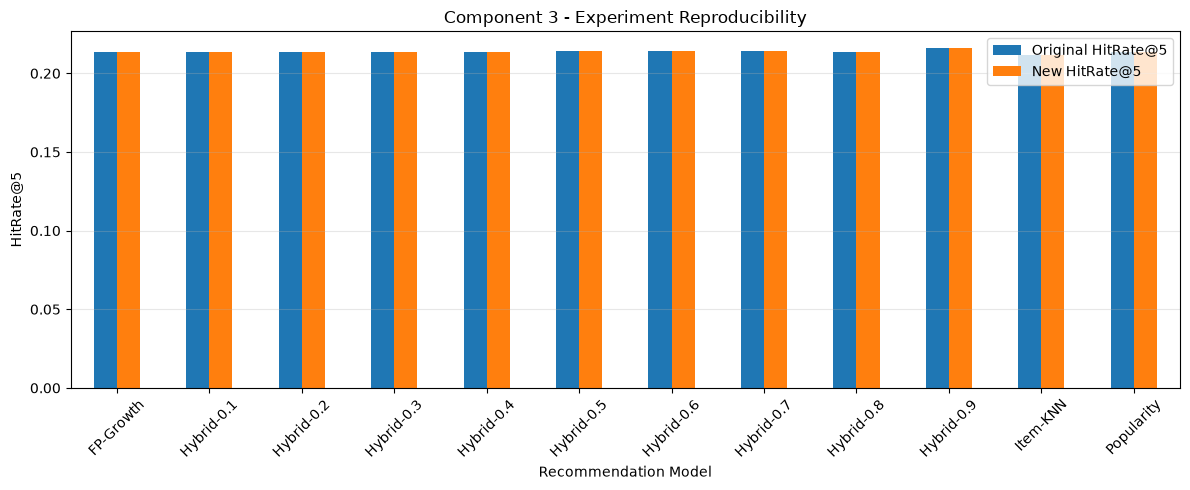

In [15]:
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Original HitRate@5": original["HitRate@5"],
    "New HitRate@5": new["HitRate@5"],
})

ax = comparison.plot(
    kind="bar",
    figsize=(12, 5),
    rot=45
)

ax.set_title("Component 3 - Experiment Reproducibility")
ax.set_xlabel("Recommendation Model")
ax.set_ylabel("HitRate@5")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

,HitRate@5,NDCG@5,HitRate Improvement (%),NDCG Improvement (%)
Model,,,,
Hybrid-0.9,0.216,0.131,1.077,1.389
Hybrid-0.5,0.214,0.130,0.375,0.540
Hybrid-0.6,0.214,0.130,0.375,0.540
Hybrid-0.7,0.214,0.130,0.187,0.463
Hybrid-0.1,0.214,0.130,0.000,0.309
Hybrid-0.2,0.214,0.130,0.000,0.309
Hybrid-0.3,0.214,0.130,0.000,0.309
Hybrid-0.4,0.214,0.130,0.000,0.309
Hybrid-0.8,0.213,0.130,-0.140,0.309


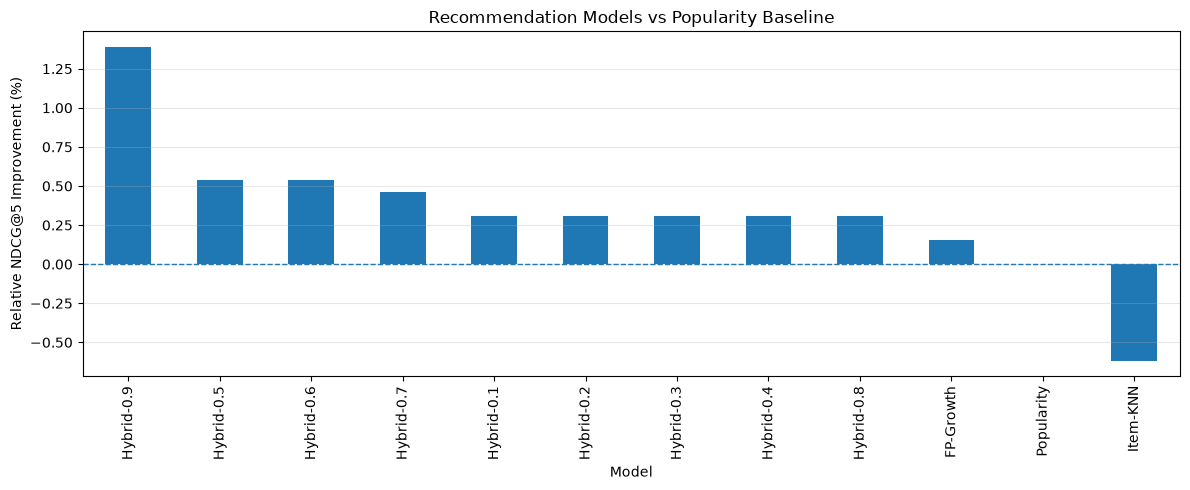

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Use reproduced validation results
results = new.copy()

baseline_hit = results.loc["Popularity", "HitRate@5"]
baseline_ndcg = results.loc["Popularity", "NDCG@5"]

comparison = results[["HitRate@5", "NDCG@5"]].copy()

comparison["HitRate Improvement (%)"] = (
    (comparison["HitRate@5"] - baseline_hit)
    / baseline_hit * 100
)

comparison["NDCG Improvement (%)"] = (
    (comparison["NDCG@5"] - baseline_ndcg)
    / baseline_ndcg * 100
)

comparison = comparison.sort_values(
    "NDCG Improvement (%)",
    ascending=False
)

display(comparison.round(3))

ax = comparison["NDCG Improvement (%)"].plot(
    kind="bar",
    figsize=(12, 5)
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_title("Recommendation Models vs Popularity Baseline")
ax.set_ylabel("Relative NDCG@5 Improvement (%)")
ax.set_xlabel("Model")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Total saved rules: 100

Association rule statistics:


,support,confidence,lift
count,100.0000,100.0000,100.0000
mean,0.0151,0.1352,1.1855
std,0.0045,0.0323,0.0316
min,0.0101,0.0764,1.1538
25%,0.0117,0.1149,1.1619
50%,0.0144,0.1343,1.1770
75%,0.0169,0.1539,1.1930
max,0.0325,0.2169,1.3011



Rules with lift >= 1.5: 0
Rules with lift >= 2.0: 0


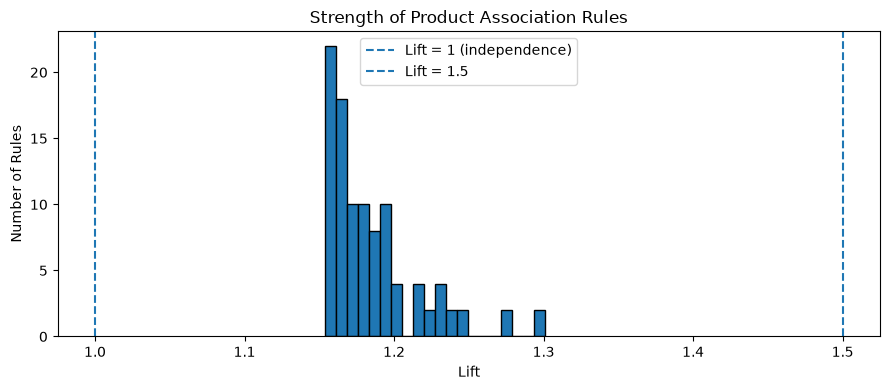

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

rules = pd.read_csv(
    EXPERIMENT_DIR / "top_rules.csv"
)

print("Total saved rules:", len(rules))
print("\nAssociation rule statistics:")

display(
    rules[["support", "confidence", "lift"]]
    .describe()
    .round(4)
)

print("\nRules with lift >= 1.5:",
      (rules["lift"] >= 1.5).sum())

print("Rules with lift >= 2.0:",
      (rules["lift"] >= 2.0).sum())

plt.figure(figsize=(9, 4))
plt.hist(rules["lift"], bins=20, edgecolor="black")
plt.axvline(1.0, linestyle="--", label="Lift = 1 (independence)")
plt.axvline(1.5, linestyle="--", label="Lift = 1.5")
plt.title("Strength of Product Association Rules")
plt.xlabel("Lift")
plt.ylabel("Number of Rules")
plt.legend()
plt.tight_layout()
plt.show()